# 02 – Complexity heatmaps: which attribute actually drives the errors?

The 1D plots in `01_overview` show errors rising with several attributes at once (length, terms, variables, …),
but these attributes are correlated: longer inputs also have more terms, more NOTs, and so on. A 2D heatmap separates
two of them: each cell holds only examples with that *combination* of values.

**How to read a heatmap**
* Each cell: share of wrong outputs among the test examples with that combination, and how many examples it has.
* Grey cells with `(n)` have fewer than `MIN_N` examples – too few to trust, so no color.
* The extra **"all"** row/column is the 1D error rate (what `01_overview` showed).
* **If the color changes when you move along x but stays the same along y, the x-attribute drives the errors** (and
  vice versa). If the color only changes along the diagonal, you can't separate the two with this data.

Section 3 then lets a small decision tree search all attributes at once for the highest-error regions ("hotspots").

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "predictions_test.csv").exists())
FIG = Path.cwd() / "figures"
FIG.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data" / "predictions_test.csv")   # unseen examples only
df["error"] = ~df["correct"]
MIN_N = 30
BASE = df["error"].mean()
print(f"{len(df):,} test examples, overall error rate {BASE:.1%}")

10,885 test examples, overall error rate 8.9%


In [2]:
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half


def bin_start(s, width):
    return (s // width) * width


def bin_label(start, width):
    return str(start) if width == 1 else f"{start}-{start + width - 1}"


def heatmap(xcol, ycol, xwidth=1, ywidth=1, min_n=MIN_N, vmax=0.5, data=None):
    """Error-rate heatmap of ycol (rows) x xcol (columns) with an 'all' row/column holding the 1D rates.
    Returns a long table of all cells (for the hotspot list)."""
    d = df if data is None else data
    xs, ys = bin_start(d[xcol], xwidth), bin_start(d[ycol], ywidth)
    xcat, ycat = sorted(xs.unique()), sorted(ys.unique())
    n = pd.crosstab(ys, xs).reindex(index=ycat, columns=xcat, fill_value=0)
    err = d.groupby([ys, xs])["error"].mean().unstack().reindex(index=ycat, columns=xcat)
    # append marginals: last column = per-row rate, last row = per-column rate
    n["all"], err["all"] = n.sum(axis=1), d.groupby(ys)["error"].mean().reindex(ycat)
    n.loc["all"] = n.sum(axis=0)
    err.loc["all"] = list(d.groupby(xs)["error"].mean().reindex(xcat)) + [d["error"].mean()]

    shown = err.where(n >= min_n).to_numpy(dtype=float)
    cmap = plt.get_cmap("Reds").copy()
    cmap.set_bad("#eeeeee")
    fig, ax = plt.subplots(figsize=(max(5, 0.75 * n.shape[1] + 2.5), max(3.5, 0.55 * n.shape[0] + 1.8)))
    im = ax.imshow(np.ma.masked_invalid(shown), cmap=cmap, vmin=0, vmax=vmax, origin="lower", aspect="auto")
    for i in range(n.shape[0]):
        for j in range(n.shape[1]):
            k, r = n.iat[i, j], err.iat[i, j]
            if k == 0:
                continue
            if k >= min_n:
                ax.text(j, i, f"{r:.0%}\n{k:,}", ha="center", va="center", fontsize=7,
                        color="white" if r > 0.6 * vmax else "black")
            else:
                ax.text(j, i, f"({k})", ha="center", va="center", fontsize=6, color="gray")
    ax.axvline(n.shape[1] - 1.5, color="black", lw=1.5)  # separate the 'all' column/row
    ax.axhline(n.shape[0] - 1.5, color="black", lw=1.5)
    ax.set_xticks(range(n.shape[1]), [bin_label(c, xwidth) for c in xcat] + ["all"], fontsize=8)
    ax.set_yticks(range(n.shape[0]), [bin_label(c, ywidth) for c in ycat] + ["all"], fontsize=8)
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f"Test error rate by {ycol} x {xcol}\n(grey = n < {min_n}; overall {BASE:.1%}; "
                 f"color capped at {vmax:.0%})", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.03, label="share of wrong outputs")
    fig.tight_layout()
    fig.savefig(FIG / f"heatmap_{ycol}_x_{xcol}.png", dpi=150)
    plt.show()

    cells = (n.drop(index="all", columns="all").stack().rename("n").to_frame()
             .join(err.drop(index="all", columns="all").stack().rename("error_rate")))
    cells["pair"] = f"{ycol} x {xcol}"
    cells.index = [f"{ycol}={bin_label(a, ywidth)}, {xcol}={bin_label(b, xwidth)}" for a, b in cells.index]
    return cells


all_cells = []

## 1. The three planned heatmaps

Note: in the test set only 102 inputs have 3 variables and depth is always 1 or 2, so some rows are thin by design.

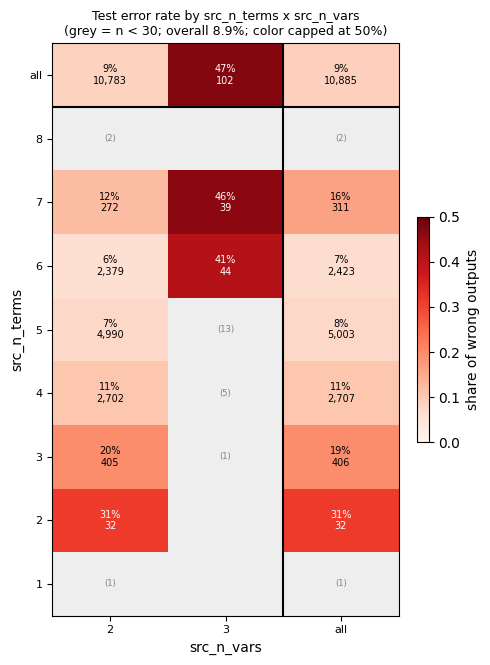

In [3]:
all_cells.append(heatmap("src_n_vars", "src_n_terms"))

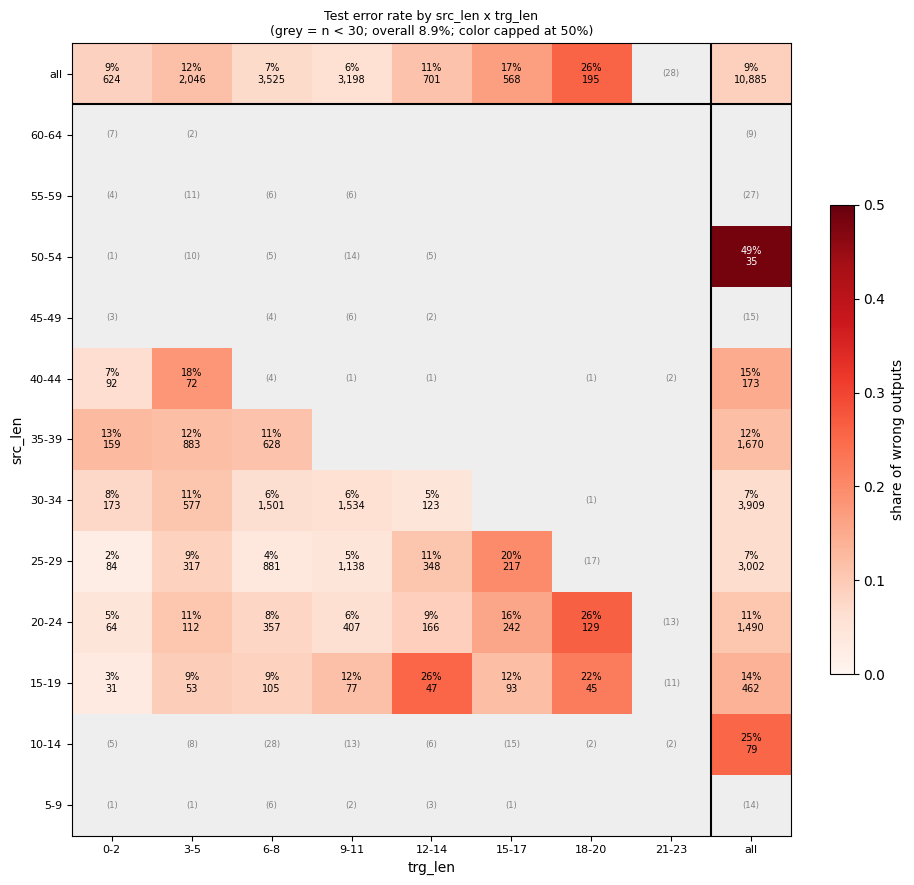

In [4]:
all_cells.append(heatmap("trg_len", "src_len", xwidth=3, ywidth=5))

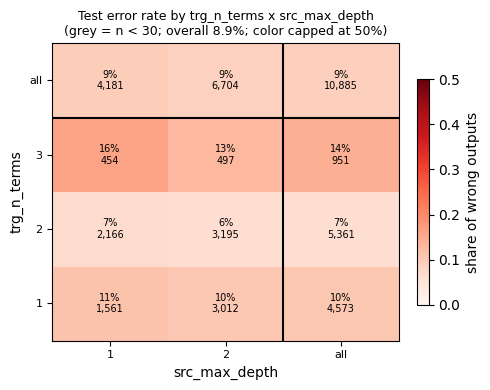

In [5]:
all_cells.append(heatmap("src_max_depth", "trg_n_terms"))

## 2. Additional pairs worth checking

* `src_len` x `src_n_terms`: the two "input size" measures, which are strongly correlated – which one matters?
* `src_n_vars` x `trg_n_vars`: inputs and targets with 3 variables were the worst bins in 1D.
* `trg_n_terms` x `trg_len`: is it the *size of the answer* rather than the size of the input?

`heatmap(xcol, ycol, xwidth, ywidth)` works for any two columns of the CSV – try your own.

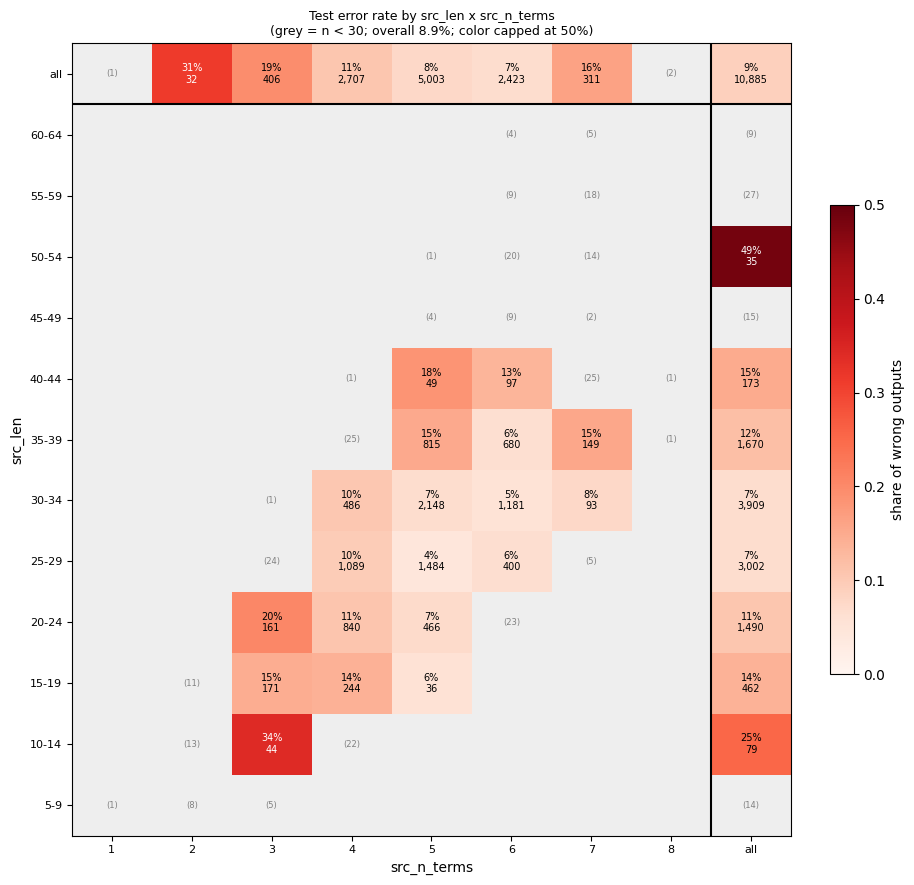

In [6]:
all_cells.append(heatmap("src_n_terms", "src_len", ywidth=5))

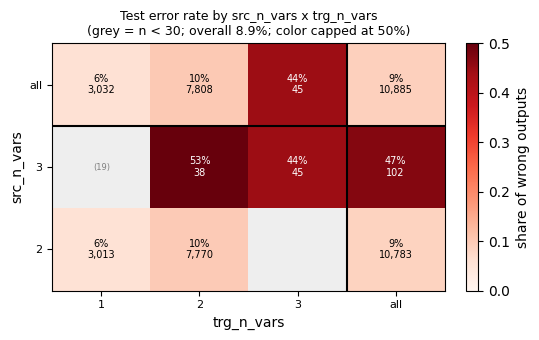

In [7]:
all_cells.append(heatmap("trg_n_vars", "src_n_vars"))

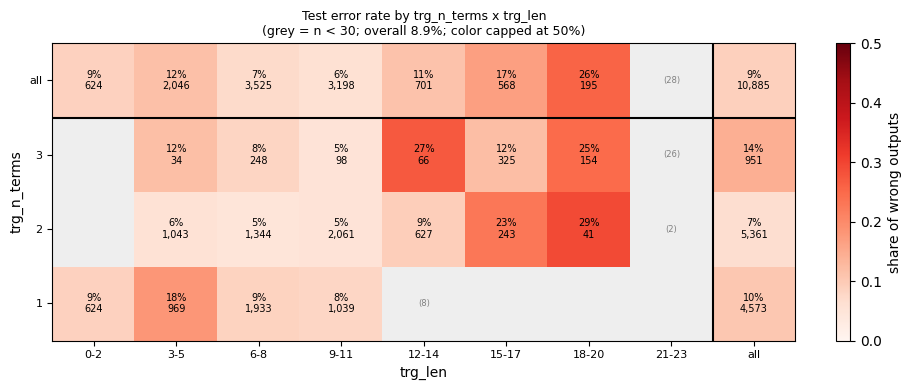

In [8]:
all_cells.append(heatmap("trg_len", "trg_n_terms", xwidth=3))

### Hotspot list from the heatmaps

All cells above with at least `MIN_N` examples, sorted by error rate. `ci_low` is the lower end of the 95% interval –
a cell is a convincing hotspot when even `ci_low` is well above the overall rate. `share_of_errors` says how much of
the model's total failure that cell accounts for (a 60% cell with 40 examples matters less than a 20% cell with 2,000).

In [9]:
cells = pd.concat(all_cells)
cells = cells[cells.n >= MIN_N].copy()
cells["errors"] = (cells.error_rate * cells.n).round().astype(int)
cells["ci_low"], cells["ci_high"] = wilson(cells.errors, cells.n)
cells["lift"] = cells.error_rate / BASE
cells["share_of_errors"] = cells.errors / df["error"].sum()
cells.sort_values("error_rate", ascending=False).head(15).round(3)

,n,error_rate,pair,errors,ci_low,ci_high,lift,share_of_errors
"src_n_vars=3, trg_n_vars=2",38,0.526,src_n_vars x trg_n_vars,20,0.373,0.675,5.888,0.021
"src_n_terms=7, src_n_vars=3",39,0.462,src_n_terms x src_n_vars,18,0.316,0.614,5.163,0.018
"src_n_vars=3, trg_n_vars=3",45,0.444,src_n_vars x trg_n_vars,20,0.309,0.588,4.972,0.021
"src_n_terms=6, src_n_vars=3",44,0.409,src_n_terms x src_n_vars,18,0.277,0.556,4.577,0.018
"src_len=10-14, src_n_terms=3",44,0.341,src_len x src_n_terms,15,0.219,0.489,3.814,0.015
"src_n_terms=2, src_n_vars=2",32,0.312,src_n_terms x src_n_vars,10,0.180,0.486,3.496,0.010
"trg_n_terms=2, trg_len=18-20",41,0.293,trg_n_terms x trg_len,12,0.176,0.445,3.274,0.012
"trg_n_terms=3, trg_len=12-14",66,0.273,trg_n_terms x trg_len,18,0.180,0.390,3.051,0.018
"src_len=20-24, trg_len=18-20",129,0.264,src_len x trg_len,34,0.195,0.346,2.949,0.035
"src_len=15-19, trg_len=12-14",47,0.255,src_len x trg_len,12,0.153,0.395,2.856,0.012


## 3. Let a decision tree search all attributes at once

A shallow tree splits the test set on whichever attribute separates wrong from right outputs best, then repeats inside
each half. Its leaves are the highest- and lowest-error regions it can find. Two caveats: when attributes are
correlated, the tree picks *one* of them (so check its choice against the heatmaps), and it only describes the data –
it doesn't prove causation. `min_samples_leaf` keeps it from chasing tiny groups.

In [12]:
from sklearn.tree import DecisionTreeClassifier, export_text

FEATURES = [c for c in df.columns if c.startswith(("src_", "trg_")) and c not in ("src", "trg")]
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=0)
tree.fit(df[FEATURES], df["error"])
print(export_text(tree, feature_names=FEATURES, show_weights=True))

|--- trg_n_not <= 1.50
|   |--- trg_max_const <= 0.50
|   |   |--- src_len <= 36.50
|   |   |   |--- weights: [1956.00, 238.00] class: False
|   |   |--- src_len >  36.50
|   |   |   |--- weights: [348.00, 109.00] class: False
|   |--- trg_max_const >  0.50
|   |   |--- trg_len <= 13.50
|   |   |   |--- weights: [6804.00, 388.00] class: False
|   |   |--- trg_len >  13.50
|   |   |   |--- weights: [304.00, 67.00] class: False
|--- trg_n_not >  1.50
|   |--- src_len <= 26.50
|   |   |--- src_n_terms <= 3.50
|   |   |   |--- weights: [88.00, 49.00] class: False
|   |   |--- src_n_terms >  3.50
|   |   |   |--- weights: [336.00, 72.00] class: False
|   |--- src_len >  26.50
|   |   |--- weights: [76.00, 50.00] class: False



In [13]:
# leaves as a table: the rule that leads there, size, error rate
t = tree.tree_
def rules(node=0, path=()):
    if t.children_left[node] == -1:
        yield node, " and ".join(path) or "(all)"
        return
    f, thr = FEATURES[t.feature[node]], t.threshold[node]
    yield from rules(t.children_left[node], path + (f"{f} <= {thr:.1f}",))
    yield from rules(t.children_right[node], path + (f"{f} > {thr:.1f}",))

leaf_of = tree.apply(df[FEATURES])
leaves = pd.DataFrame([{"rule": r, "n": int((leaf_of == node).sum()),
                        "error_rate": df["error"][leaf_of == node].mean()} for node, r in rules()])
leaves["errors"] = (leaves.error_rate * leaves.n).round().astype(int)
leaves["ci_low"], leaves["ci_high"] = wilson(leaves.errors, leaves.n)
leaves["share_of_errors"] = leaves.errors / df["error"].sum()
leaves.sort_values("error_rate", ascending=False).round(3)

,rule,n,error_rate,errors,ci_low,ci_high,share_of_errors
6,trg_n_not > 1.5 and src_len > 26.5,126,0.397,50,0.316,0.484,0.051
4,trg_n_not > 1.5 and src_len <= 26.5 and src_n_...,137,0.358,49,0.282,0.441,0.050
1,trg_n_not <= 1.5 and trg_max_const <= 0.5 and ...,457,0.239,109,0.202,0.280,0.112
3,trg_n_not <= 1.5 and trg_max_const > 0.5 and t...,371,0.181,67,0.145,0.223,0.069
5,trg_n_not > 1.5 and src_len <= 26.5 and src_n_...,408,0.176,72,0.143,0.216,0.074
0,trg_n_not <= 1.5 and trg_max_const <= 0.5 and ...,2194,0.108,238,0.096,0.122,0.245
2,trg_n_not <= 1.5 and trg_max_const > 0.5 and t...,7192,0.054,388,0.049,0.059,0.399


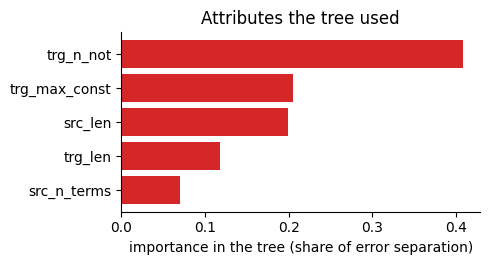

In [14]:
imp = pd.Series(tree.feature_importances_, index=FEATURES).sort_values()
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(5, 0.35 * len(imp) + 1))
ax.barh(imp.index, imp.values, color="tab:red")
ax.set_xlabel("importance in the tree (share of error separation)")
ax.set_title("Attributes the tree used")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "tree_importance.png", dpi=150)

## 4. Look at examples from a hotspot

Numbers only go so far – read some actual inputs/outputs from the worst region. Change the filter to any hotspot.

In [15]:
hot = df[(df.src_n_vars == 3)]
print(f"{len(hot)} examples, error rate {hot.error.mean():.1%}")
hot.loc[hot.error, ["src", "trg", "pred", "verdict", "min_tok_prob"]].head(10)

102 examples, error rate 47.1%


,src,trg,pred,verdict,min_tok_prob
402,-2*(x&~y^z)-4*(~x&(~y|~z))+4*(~x|y^~z)-(~y^z)-...,-2*(~x&~y),-5*(~x&~y),wrong,0.364593
425,(~y)+2*(~x&~z)-(~x|y^~z)-(x|y&~z)+(y^~z)+(x&y)...,-3*(x|y|z),-(x|y|z),wrong,0.813533
455,-2*(x|~y|z)-2*(x|~y&~z)+3*(x|~y)+2*(x^y&z)+(y^...,z,-(x|y|z),wrong,0.746291
714,(x&~y^z)+2*(~x&~z)+2*(x|~y)-2*(x|y&~z)-(y^~z),3*(~x&~y),3*(~x&(y^z)),wrong,0.805542
780,(~x&~y|z)-(~x&y^z)+2*(~x|y^~z)+(x|y&~z)-2*(y^~...,~x&(y^z),~x&~y,wrong,0.852283
921,(x&~y^z)-(~x&~z)+2*(x^~z)+2*(~x&y^~z)-(y^~z)-(...,-(~x&(y^z)),~x&(y^z),wrong,0.654207
1175,2*(x&~y^z)+2*(~x|~z)+2*(x^~z)-(~y^z)-(y^~z)-(-...,2*(~x&(y^z)),~x&(y^z),wrong,0.651948
1734,-2*(~x&~y|z)+2*(~x|~z)+2*(x^~z)-(~x&y^~z)-(x|~...,-z,z,wrong,0.963915
1813,(~x&~y|z)+(~x|~z)+(x|~y)+(x|y&~z)-(x|y^z)-(x|y...,~x&~y,~x&(y^z),wrong,0.949720
1880,(~y)+(~x&(~y|~z))+(x^~z)+(~x&y^~z)-(x|y^z)+(x&...,-3*(x|y|z),-2*(x|y|z),wrong,0.946900


## Answering the question

Write down one or two hotspots in this form – it's what goes into the group discussion and the video:

> *"Among unseen examples, the model fails on X% of inputs with [condition] (n = …), vs. Y% overall. This holds within
> each level of [the correlated attribute], so it's [attribute] and not [other attribute] that matters."*